<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/A6_intermediate_presentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The relationship between lifestyle habits, physical activity, and weight classification

**Leylah Fragoso Carvajal #A01178568**


*INDEX:*
1. [Describing the dataset](#scrollTo=ICeIJrvwv4jm&line=1&uniqifier=1)
2. [Describing the variables of interest](#scrollTo=F9owDlztv7N8&line=1&uniqifier=1)
3. [Study Roadmap summary](#scrollTo=XqnDwwKdYm0S&line=1&uniqifier=1)
4. [Q1: How are individuals distributed across different weight classifications?](#scrollTo=zhbaN-S_wE3X&line=1&uniqifier=1) **Pie Chart**
5. [Q2: How does the percentage of individuals classified with obesity differ depending on their family overweight history?](#scrollTo=8rO55TFrxAPO&line=2&uniqifier=1) **Bar Chart**
6. [Q3:  How does physical activity frequency differ between individuals with obesity and other weight classifications?](#scrollTo=pOqKcatK9Tzo&line=1&uniqifier=1) **Histogram**
7. [Q4: What is the relationship between vegetable consumption frequency and physical activity frequency?](#scrollTo=7IW8RxGj_cYj&line=1&uniqifier=1) **Scatterplot**
8. [Q5:How does the distribution of weight classifications differ between females and males?](#scrollTo=R3GUW9HXBGWl&line=1&uniqifier=1)**Heatmap**
9. [Q6: How does vegetable consumption frequency vary across different weight classifications?](#scrollTo=q7liQ-Z3CanA&line=1&uniqifier=1) **Boxplot**
10. [Q7:How does the distribution of weight classifications differ depending on frequent high-calorie food consumption?](#scrollTo=9bxwS85yIk_6&line=1&uniqifier=1)**Lineplot**
11. [Q8: To what extent does physical activity frequency explain variations in daily water intake](#scrollTo=eXQoGNJ5N14P&line=1&uniqifier=1)**Linear regression**
12. [Overall conclusion](#scrollTo=LdYXbb7cZhaR&line=1&uniqifier=1)

In [61]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import seaborn as sns


In [62]:
path = '/content/ObesityDataSet_raw_and_data_sinthetic.csv'
df = pd.read_csv(path)
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


# [1. Describing the data set](#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1)

The dataset describes individuals' eating habits, physical activity, family history, and physical characteristics, along with their corresponding weight classifications. It includes variables related to food consumption, daily water intake, meal frequency, and transportation habits.

**Important limitation:** The dataset contains both collected and synthetically generated observations. Therefore, the distribution of weight classifications should not be interpreted as representative of obesity prevalence in the general population.

**Dataset's Name:** Estimation of Obesity Levels Based On Eating Habits and Physical Condition

**Source:**
[UC Irvine’s Machine Learning Repository](https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition )


**Data Type:** Categorical, Numerical (continuous and integers) and Binary


**Observations:** 2111 observations

**Unit of obervation:** Each row represents one individual's physical characteristics, eating habits, lifestyle information, and weight classification.

## 1.1 Introduction to the dataset



In [63]:
df.shape

(2111, 17)

In [64]:
print('The data set has: \n',df.shape[0], 'observations and ', df.shape[1], ' columns')

The data set has: 
 2111 observations and  17  columns


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [66]:

for col in df.columns:

    if df[col].dtype == 'object':
        if df[col].nunique() == 2:
            print(col, ": Binary")
        else:
            print(col, ": Categorical")

    elif df[col].dtype == 'int64':
        print(col, ": Integer")

    elif df[col].dtype == 'float64':
        print(col, ": Continuous")

Gender : Binary
Age : Continuous
Height : Continuous
Weight : Continuous
family_history_with_overweight : Binary
FAVC : Binary
FCVC : Continuous
NCP : Continuous
CAEC : Categorical
SMOKE : Binary
CH2O : Continuous
SCC : Binary
FAF : Continuous
TUE : Continuous
CALC : Categorical
MTRANS : Categorical
NObeyesdad : Categorical


## 1.2 Data Quality

In this section, I checked for missing and duplicated observations to assess data quality.

### Null values

In [67]:
df.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


In [68]:
df.dropna(inplace=True)
df.shape

(2111, 17)

Even after double checking, by eliminating the rows that have at least one missing value. As seen in the previous code line, the shape of the data frame is the same as the original. There for it had no missing values.

### Duplicated values

In [69]:
df.duplicated().sum()

np.int64(24)

In [70]:
print('The data set has:\n', df.duplicated().sum(), 'duplicated observations')

The data set has:
 24 duplicated observations


In [71]:
df.drop_duplicates(inplace=True)
ndf = df.copy()
ndf

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000000,1.620000,64.000000,yes,no,2.0,3.0,Sometimes,no,2.000000,no,0.000000,1.000000,no,Public_Transportation,Normal_Weight
1,Female,21.000000,1.520000,56.000000,yes,no,3.0,3.0,Sometimes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000000,1.800000,77.000000,yes,no,2.0,3.0,Sometimes,no,2.000000,no,2.000000,1.000000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000000,1.800000,87.000000,no,no,3.0,3.0,Sometimes,no,2.000000,no,2.000000,0.000000,Frequently,Walking,Overweight_Level_I
4,Male,22.000000,1.780000,89.800000,no,no,2.0,1.0,Sometimes,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,Female,20.976842,1.710730,131.408528,yes,yes,3.0,3.0,Sometimes,no,1.728139,no,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,Female,21.982942,1.748584,133.742943,yes,yes,3.0,3.0,Sometimes,no,2.005130,no,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,Female,22.524036,1.752206,133.689352,yes,yes,3.0,3.0,Sometimes,no,2.054193,no,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,Female,24.361936,1.739450,133.346641,yes,yes,3.0,3.0,Sometimes,no,2.852339,no,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


In [72]:
ndf.shape

(2087, 17)

In [73]:
print ('After dropping duplicated values, the data set has:\n',ndf.shape[0],'rows and ', ndf.shape[1], ' columns')

After dropping duplicated values, the data set has:
 2087 rows and  17  columns


# [2. Describing the variables of interest](#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1)

In this section I'll and keep only the variables that interest me, given my research topic.

**Variables of Interest**
1.  **family_history:**
  Indicates whether an individual has family members who currently have or previously had overweight. *(Binary)*
2.  **Weight_class:** Represents an individual's weight classification, ranging from insufficient weight to different obesity levels. *(Categorical)*

3.  **High_calorie:** Indicates whether an individual frequently consumes high-calorie foods. *(Binary)*
4.  **Veggies_freq:** Measures how frequently an individual consumes vegetables in their meals. *(Numerical)*
5.  **Water_intake**  Represents an individual's reported daily water consumption. *(Numerical)*
6.  **Physical_Act:** Measures how frequently an individual engages in physical activity. *(Numerical)*
7. **Gender_binary** : Individual's gender: 1- female or 2 -male *(binary)*




In [74]:
# Select variables of interest

interest_variables = [
    'family_history_with_overweight',
    'FAVC', 'FCVC', 'CH2O',
    'FAF','NObeyesdad', 'Gender'
]

# update data set with variables of interest
ndf = df[interest_variables].copy()

# Rename variables
ndf.rename(columns={
    'family_history_with_overweight': 'family_history',
    'FAVC': 'High_calorie',
    'FCVC': 'Veggies_freq',
    'CH2O': 'Water_intake',
    'FAF': 'Physical_Act',
    'NObeyesdad': 'Weight_class'
}, inplace=True)

ndf.head()

,family_history,High_calorie,Veggies_freq,Water_intake,Physical_Act,Weight_class,Gender
0,yes,no,2.0,2.0,0.0,Normal_Weight,Female
1,yes,no,3.0,3.0,3.0,Normal_Weight,Female
2,yes,no,2.0,2.0,2.0,Normal_Weight,Male
3,no,no,3.0,2.0,2.0,Overweight_Level_I,Male
4,no,no,2.0,2.0,0.0,Overweight_Level_II,Male


In [75]:
# Encode Gender as a binary numerical variable

ndf['Gender_binary'] = ndf['Gender'].map({
    'Female': 1,
    'Male': 2
})

ndf[['Gender', 'Gender_binary']].head()

,Gender,Gender_binary
0,Female,1
1,Female,1
2,Male,2
3,Male,2
4,Male,2


In [76]:
# Classify variables based on their values

variable_types = {}

for col in ndf.columns:

    if ndf[col].nunique() == 2:
        var_type = 'Binary'

    elif ndf[col].dtype == 'object':
        var_type = 'Categorical'

    else:
        var_type = 'Numerical'

    variable_types[col] = var_type

In [77]:
ndf['Gender_binary'].value_counts()

,count
Gender_binary,
2,1052
1,1035


In [78]:
print(ndf.columns.tolist())
print("Number of columns:", len(ndf.columns))

['family_history', 'High_calorie', 'Veggies_freq', 'Water_intake', 'Physical_Act', 'Weight_class', 'Gender', 'Gender_binary']
Number of columns: 8


In [79]:
# Remove original Gender variable
ndf.drop(columns=['Gender'], inplace=True)

# Verify the remaining columns
ndf.head()

,family_history,High_calorie,Veggies_freq,Water_intake,Physical_Act,Weight_class,Gender_binary
0,yes,no,2.0,2.0,0.0,Normal_Weight,1
1,yes,no,3.0,3.0,3.0,Normal_Weight,1
2,yes,no,2.0,2.0,2.0,Normal_Weight,2
3,no,no,3.0,2.0,2.0,Overweight_Level_I,2
4,no,no,2.0,2.0,0.0,Overweight_Level_II,2


In [80]:
print(ndf.columns.tolist())
print("Number of variables:", len(ndf.columns))

['family_history', 'High_calorie', 'Veggies_freq', 'Water_intake', 'Physical_Act', 'Weight_class', 'Gender_binary']
Number of variables: 7


In [81]:
variables_table = pd.DataFrame({
    'Variable': ndf.columns,

    'Meaning': [
        'Family history of overweight',
        'Frequent consumption of high-calorie food',
        'Frequency of vegetable consumption',
        'Daily water consumption',
        'Frequency of physical activity',
        'Weight classification',
        'Gender encoded as a binary numerical value'
    ],

    'Unit / Categories': [
        'Yes / No',
        'Yes / No',
        'Frequency scale (1-3)',
        'Intake scale (1-3)',
        'Activity frequency scale (0-3)',
        'Underweight, Normal weight, Overweight I-II, Obesity I-III',
        '1 / 2',

    ]
})

# Add previously identified types
variables_table['Type'] = variables_table['Variable'].map(variable_types)

# Arrange columns
variables_table = variables_table[
    ['Variable', 'Meaning', 'Type', 'Unit / Categories']
]

display(variables_table)

,Variable,Meaning,Type,Unit / Categories
0,family_history,Family history of overweight,Binary,Yes / No
1,High_calorie,Frequent consumption of high-calorie food,Binary,Yes / No
2,Veggies_freq,Frequency of vegetable consumption,Numerical,Frequency scale (1-3)
3,Water_intake,Daily water consumption,Numerical,Intake scale (1-3)
4,Physical_Act,Frequency of physical activity,Numerical,Activity frequency scale (0-3)
5,Weight_class,Weight classification,Categorical,"Underweight, Normal weight, Overweight I-II, O..."
6,Gender_binary,Gender encoded as a binary numerical value,Binary,1 / 2


# [Study roadmap](#scrollTo=u9q-QGBEvqn_&line=18&uniqifier=1)

In [102]:
# Create the 8-study analytical roadmap

roadmap = pd.DataFrame({
    'Study': [1, 2, 3, 4, 5, 6, 7, 8],

    'Research Question': [
        'Weight classification distribution',
        'Obesity and family history',
        'Physical activity and obesity',
        'Vegetable consumption and activity',
        'Weight classification by gender',
        'Vegetable consumption by weight class',
        'High-calorie food and weight class',
        'Physical activity and water intake'
    ],

    'Figure': [
        'Pie Chart',
        'Bar Chart',
        'Histogram',
        'Scatter Plot',
        'Heatmap',
        'Box Plot',
        'Line Plot',
        'OLS Regression'
    ],

    'Main Insight': [
        'Obesity I was the largest group (16.8%)',
        '56.0% vs 2.2% obesity by family history',
        'Both groups peak at zero activity',
        'No clear linear relationship',
        'Obesity II and III differ by gender',
        'Obesity I shows lower outliers',
        'Frequent consumers show higher obesity proportions',
        'Significant relationship, but R² = 0.027'
    ]
})

display(roadmap)

,Study,Research Question,Figure,Main Insight
0,1,Weight classification distribution,Pie Chart,Obesity I was the largest group (16.8%)
1,2,Obesity and family history,Bar Chart,56.0% vs 2.2% obesity by family history
2,3,Physical activity and obesity,Histogram,Both groups peak at zero activity
3,4,Vegetable consumption and activity,Scatter Plot,No clear linear relationship
4,5,Weight classification by gender,Heatmap,Obesity II and III differ by gender
5,6,Vegetable consumption by weight class,Box Plot,Obesity I shows lower outliers
6,7,High-calorie food and weight class,Line Plot,Frequent consumers show higher obesity proport...
7,8,Physical activity and water intake,OLS Regression,"Significant relationship, but R² = 0.027"


# [3. Q1: How are individuals distributed across different weight classifications?]((#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1)) **Pie chart**



## 3.1 Pivot table

To count how many individuals fall into each of the NObeyesda categories.


In [82]:
weight_gp_count = pd.pivot_table(
    ndf,
    index='Weight_class',
    aggfunc='size'
).reset_index(name='count_WeightGP')

weight_gp_count

,Weight_class,count_WeightGP
0,Insufficient_Weight,267
1,Normal_Weight,282
2,Obesity_Type_I,351
3,Obesity_Type_II,297
4,Obesity_Type_III,324
5,Overweight_Level_I,276
6,Overweight_Level_II,290


## 3.2 Figure 1.- Pie chart

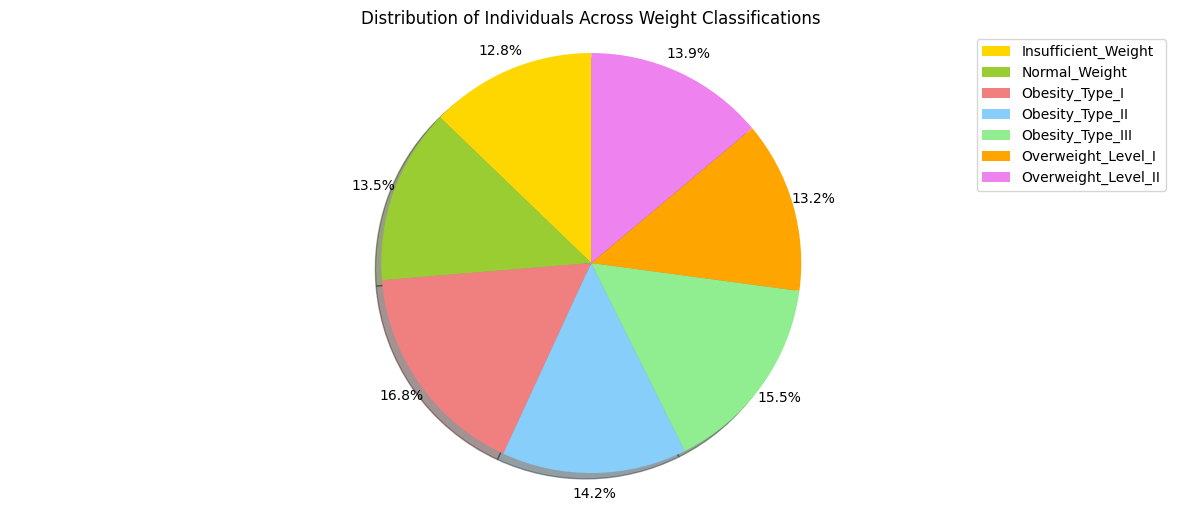

In [83]:


colors_list = ['gold', 'yellowgreen', 'lightcoral',
               'lightskyblue', 'lightgreen', 'orange', 'violet']

explode_list = [0, 0, 0, 0, 0, 0, 0]

# Plot the pie chart

weight_gp_count['count_WeightGP'].plot(
    kind='pie',
    figsize=(15, 6),
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    labels=None,
    pctdistance=1.1,
    explode=explode_list,
    colors=colors_list
)

plt.axis('equal')

plt.legend(
    labels=weight_gp_count['Weight_class'],
    bbox_to_anchor=(1.0, 1.0)
)

plt.title('Distribution of Individuals Across Weight Classifications')
plt.ylabel('')
plt.show()

## 3.3 Insights

1. Obesity Type I had the highest proportion (16.8%), exceeding the Normal Weight group (13.5%) by 3.3 percentage points.

2. Insufficient Weight (12.8%) and Normal Weight (13.5%) represented the two smallest groups.

# [4. Q2: How does the percentage of individuals classified with obesity differ depending on their family overweight history?](#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1) **Bar Chart**




### 4.1 Identify people with any type of obesity

In [84]:
ndf['has_obesity'] = ndf['Weight_class'].isin([
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
])

ndf.head()

,family_history,High_calorie,Veggies_freq,Water_intake,Physical_Act,Weight_class,Gender_binary,has_obesity
0,yes,no,2.0,2.0,0.0,Normal_Weight,1,False
1,yes,no,3.0,3.0,3.0,Normal_Weight,1,False
2,yes,no,2.0,2.0,2.0,Normal_Weight,2,False
3,no,no,3.0,2.0,2.0,Overweight_Level_I,2,False
4,no,no,2.0,2.0,0.0,Overweight_Level_II,2,False


### 4.2 Pivot table to count observations by family history and obesity classification

In [85]:
family_gp_count = pd.pivot_table(
    ndf,
    index='family_history',
    columns='has_obesity',
    aggfunc='size',
    fill_value=0
)

family_gp_count

has_obesity,False,True
family_history,,
no,357,8
yes,758,964


In [86]:
# Calculate obesity percentage within each family history group

family_gp_count['Obesity_Percentage'] = (
    family_gp_count[True] /
    family_gp_count.sum(axis=1) * 100
)

family_gp_count

has_obesity,False,True,Obesity_Percentage
family_history,,,
no,357,8,2.191781
yes,758,964,55.981417


### 4.3 Figure 2.- Bar chart

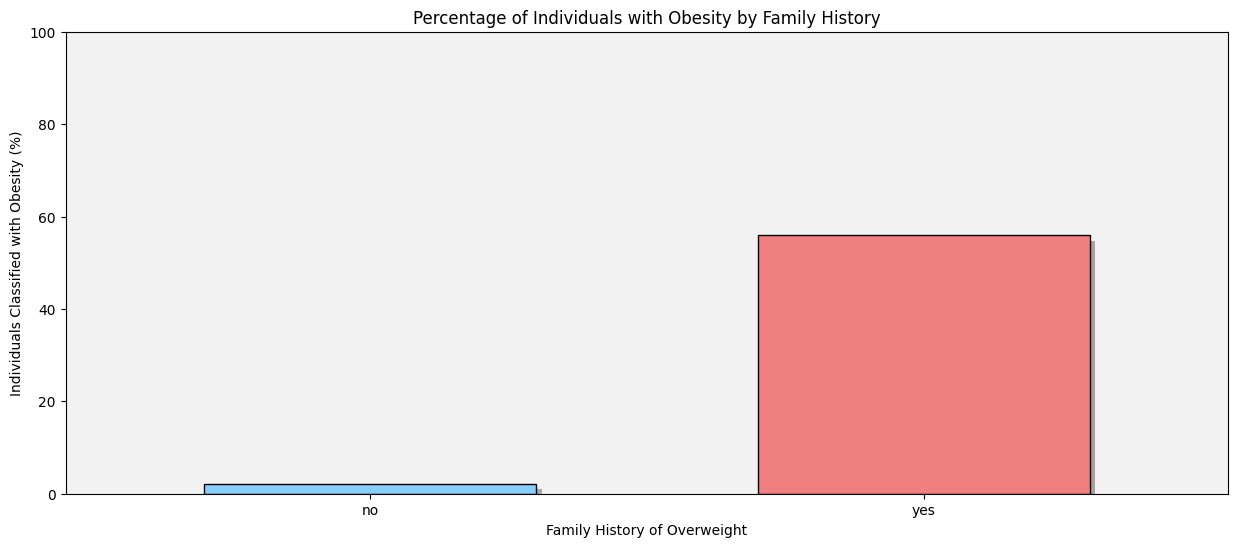

In [87]:
import matplotlib.patheffects as pe

colors_list = ['lightskyblue', 'lightcoral']

ax = family_gp_count['Obesity_Percentage'].plot(
    kind='bar',
    figsize=(15, 6),
    color=colors_list,
    edgecolor='black',
    width=0.6
)

# Set light grey background
ax.set_facecolor('#F2F2F2')

# Add shadows
for bar in ax.patches:
    bar.set_path_effects([
        pe.SimplePatchShadow(offset=(4, -4), alpha=0.4),
        pe.Normal()
    ])

plt.title('Percentage of Individuals with Obesity by Family History')
plt.xlabel('Family History of Overweight')
plt.ylabel('Individuals Classified with Obesity (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

### 4.4 Insight

1. Individuals with a family history of overweight had a considerably higher percentage classified with obesity (55.98%) compared to those without a family history (2.19%).



##

# [5. Q3: How does physical activity frequency differ between individuals with obesity and other weight classifications?](#scrollTo=u9q-QGBEvqn_&line=11&uniqifier=1) **histogram**

In [88]:


# Separate observations into two groups
obesity_group = ndf[ndf['has_obesity'] == True]
other_group = ndf[ndf['has_obesity'] == False]


## 5.1 Figure 3. Histogram

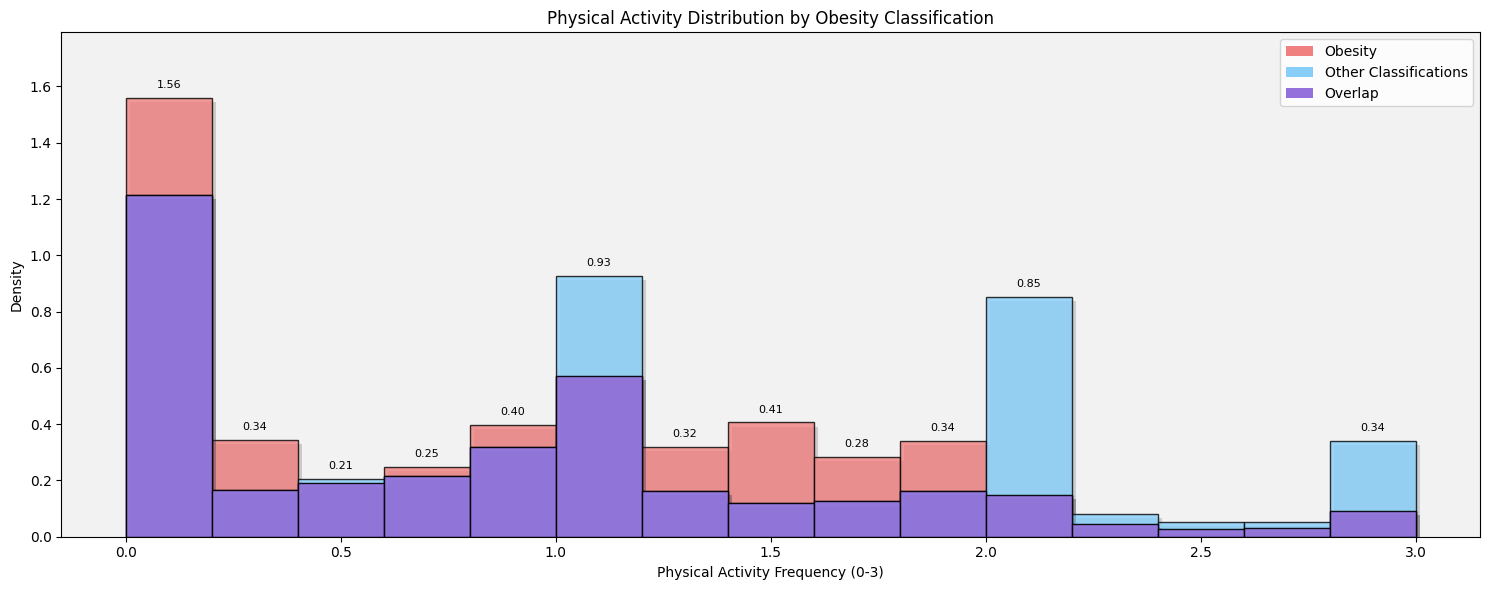

In [89]:


from matplotlib.patches import Patch

# Define the bins and calculate histogram densities
bins = np.linspace(0, 3, 16)

obesity_density, edges = np.histogram(
    obesity_group['Physical_Act'],
    bins=bins,
    density=True
)

other_density, edges = np.histogram(
    other_group['Physical_Act'],
    bins=bins,
    density=True
)

# Find the overlapping density
overlap = np.minimum(obesity_density, other_density)

# Define bar positions
positions = edges[:-1]
widths = np.diff(edges)

fig, ax = plt.subplots(figsize=(15, 6))

# Plot both distributions
ax.bar(
    positions, obesity_density,
    width=widths, align='edge',
    color='lightcoral',
    edgecolor='black',
    alpha=0.8
)

ax.bar(
    positions, other_density,
    width=widths, align='edge',
    color='lightskyblue',
    edgecolor='black',
    alpha=0.8
)

# Add explicit purple overlap
ax.bar(
    positions, overlap,
    width=widths, align='edge',
    color='mediumpurple',
    edgecolor='black',
    alpha=0.9
)

# Add shadows
for bar in ax.patches:
    bar.set_path_effects([
        pe.SimplePatchShadow(offset=(3, -3), alpha=0.2),
        pe.Normal()
    ])

# Add numerical density labels
for i in range(len(positions)):
    maximum = max(obesity_density[i], other_density[i])

    if maximum > 0.1:
        ax.text(
            positions[i] + widths[i] / 2,
            maximum + 0.035,
            f'{maximum:.2f}',
            ha='center',
            fontsize=8
        )

# Set background
ax.set_facecolor('#F2F2F2')

# Legend
legend_elements = [
    Patch(facecolor='lightcoral', label='Obesity'),
    Patch(facecolor='lightskyblue', label='Other Classifications'),
    Patch(facecolor='mediumpurple', label='Overlap')
]

ax.legend(handles=legend_elements)

# Titles and labels
plt.title('Physical Activity Distribution by Obesity Classification')
plt.xlabel('Physical Activity Frequency (0-3)')
plt.ylabel('Density')

plt.ylim(0, max(obesity_density.max(), other_density.max()) * 1.15)
plt.tight_layout()
plt.show()

**Color purple  means that both groups have observations within the same physical activity frequency interval.**

## 5.2 Insight

1. Both groups show an irregular distribution, with the highest concentration of individuals at a physical activity frequency of 0.

2. Individuals in other weight classifications show higher concentrations around activity levels 1, 2, and 3, while those classified with obesity are more concentrated at lower and intermediate activity levels.

# [6. Q4: What is the relationship between vegetable consumption frequency and physical activity frequency?](#scrollTo=u9q-QGBEvqn_) **Scatterplot**

## 6.2 Figure 4. Scatterplot of veggies consumptiom and physical activity

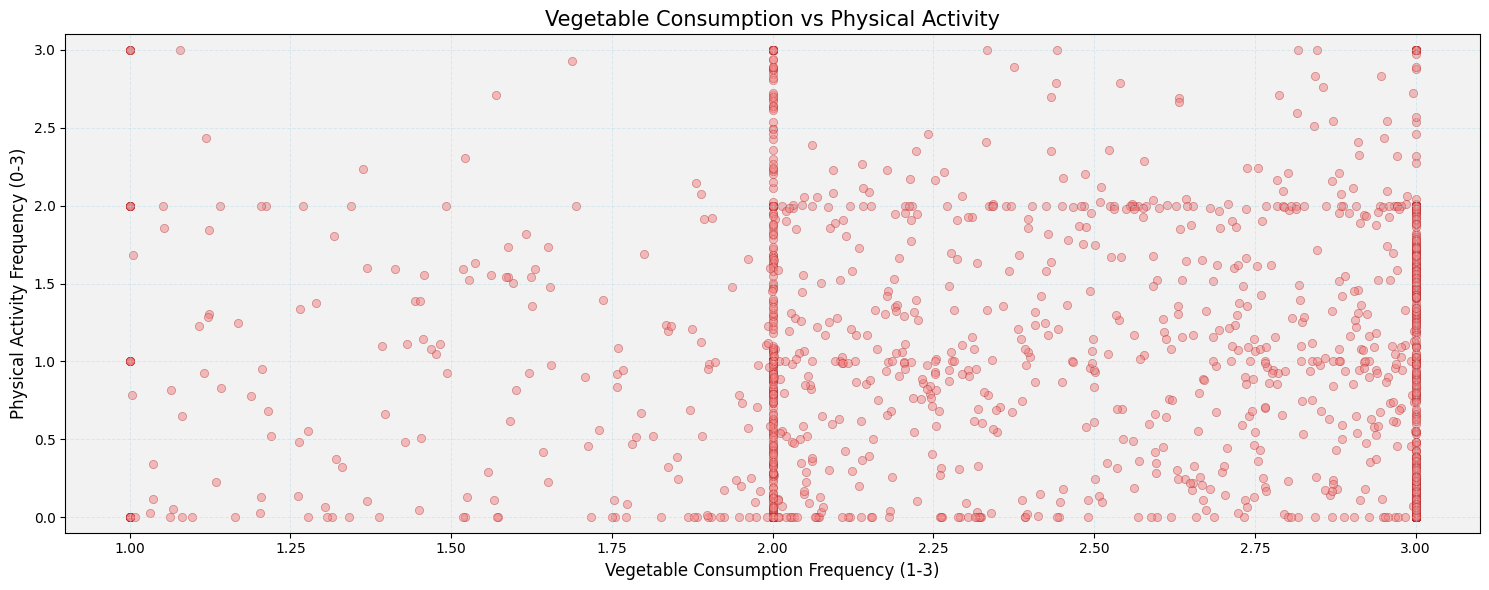

In [90]:
plt.figure(figsize=(15, 6))

plt.scatter(
    ndf['Veggies_freq'],
    ndf['Physical_Act'],
    color='lightcoral',
    edgecolor='firebrick',
    s=35,
    alpha=0.5,
    linewidth=0.5
)

# Light grey background
plt.gca().set_facecolor('#F2F2F2')

#  blue grid
plt.grid(
    True,
    color='lightblue',
    linestyle='--',
    linewidth=0.7,
    alpha=0.4
)

# Titles and labels
plt.title('Vegetable Consumption vs Physical Activity', fontsize=15)
plt.xlabel('Vegetable Consumption Frequency (1-3)', fontsize=12)
plt.ylabel('Physical Activity Frequency (0-3)', fontsize=12)

plt.xlim(0.9, 3.1)
plt.ylim(-0.1, 3.1)

plt.tight_layout()
plt.show()

## 6.2 Insight

1. The scatter plot shows no clear linear relationship between vegetable consumption and physical activity, as the observations are widely dispersed without a consistent trend.

# [7. Q5 :How does the distribution of weight classifications differ between females and males?](#scrollTo=u9q-QGBEvqn_)**Heatmap**



## 7.1 Pivot table

In [91]:
# Count individuals by gender and weight classification

gender_pivot = pd.pivot_table(
    ndf,
    index='Gender_binary',
    columns='Weight_class',
    aggfunc='size',
    fill_value=0
)

# Calculate percentages within each gender
gender_pct = gender_pivot.div(
    gender_pivot.sum(axis=1),
    axis=0
) * 100

# Rename gender categories
gender_pct.index = gender_pct.index.map({
    1: 'Female',
    2: 'Male'
})

display(gender_pct.round(1))

Weight_class,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
Gender_binary,,,,,,,
Female,16.3,13.2,15.1,0.2,31.2,14.0,10.0
Male,9.3,13.8,18.5,28.0,0.1,12.5,17.8


## 7.2 Figure 5 . Heatmap

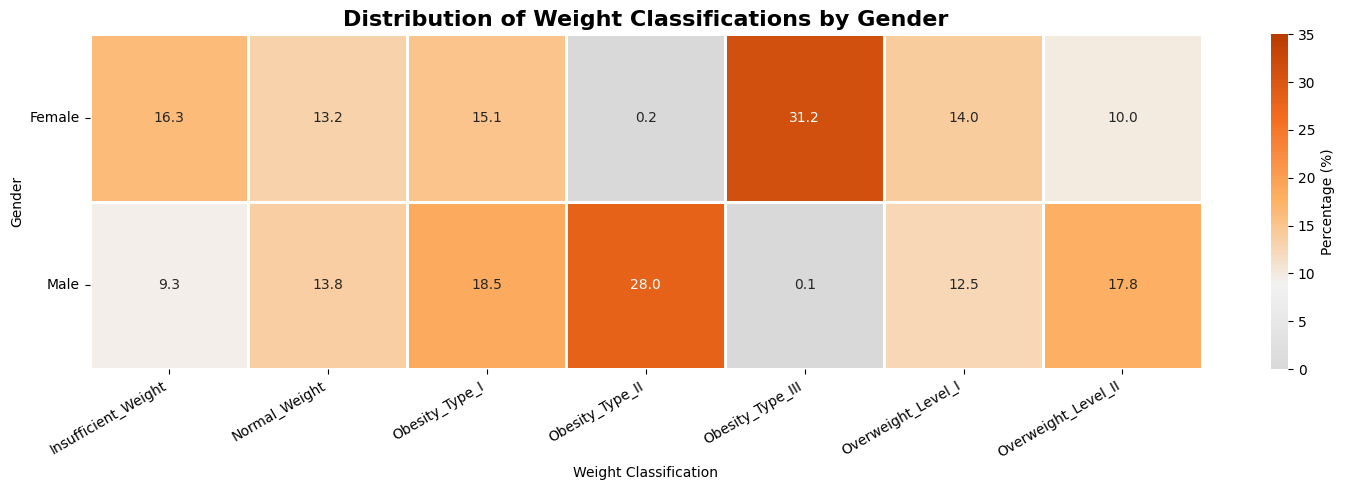

In [92]:
from matplotlib.colors import LinearSegmentedColormap

# Custom colors: Grey to Orange
colors_list = ['#D9D9D9', '#F2F2F2', '#FDB366', '#F46D20', '#B83B00']

custom_cmap = LinearSegmentedColormap.from_list(
    'Grey_Orange',
    colors_list
)

plt.figure(figsize=(15, 5))

ax = sns.heatmap(
    gender_pct,
    annot=True,
    fmt='.1f',
    cmap=custom_cmap,
    linewidths=2,
    linecolor='white',
    vmin=0,
    vmax=35,
    cbar_kws={'label': 'Percentage (%)'}
)

plt.title(
    'Distribution of Weight Classifications by Gender',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Weight Classification')
plt.ylabel('Gender')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

## 7.3 Insights

1. Obesity Type III had the highest proportion among females (31.2%), while Obesity Type II was the most represented classification among males (28.0%).

2. Obesity Type II was almost absent among females (0.2%), while Obesity Type III was almost absent among males (0.1%), showing a clear difference in the distribution of obesity levels by gender.

# [8. Q6: How does vegetable consumption frequency vary across different weight classifications?](#scrollTo=u9q-QGBEvqn_&line=14&uniqifier=1) **Boxplot**

## 8.1 Pivot table

In [93]:


vegetables = pd.pivot_table(
    ndf,
    index=ndf.index,
    values='Veggies_freq',
    columns='Weight_class'
)

vegetables.head()

Weight_class,Insufficient_Weight,Normal_Weight,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III,Overweight_Level_I,Overweight_Level_II
0,NaN,2.0,NaN,NaN,NaN,NaN,NaN
1,NaN,3.0,NaN,NaN,NaN,NaN,NaN
2,NaN,2.0,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,3.0,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,2.0


## 8.2 Figure 6. Boxplot

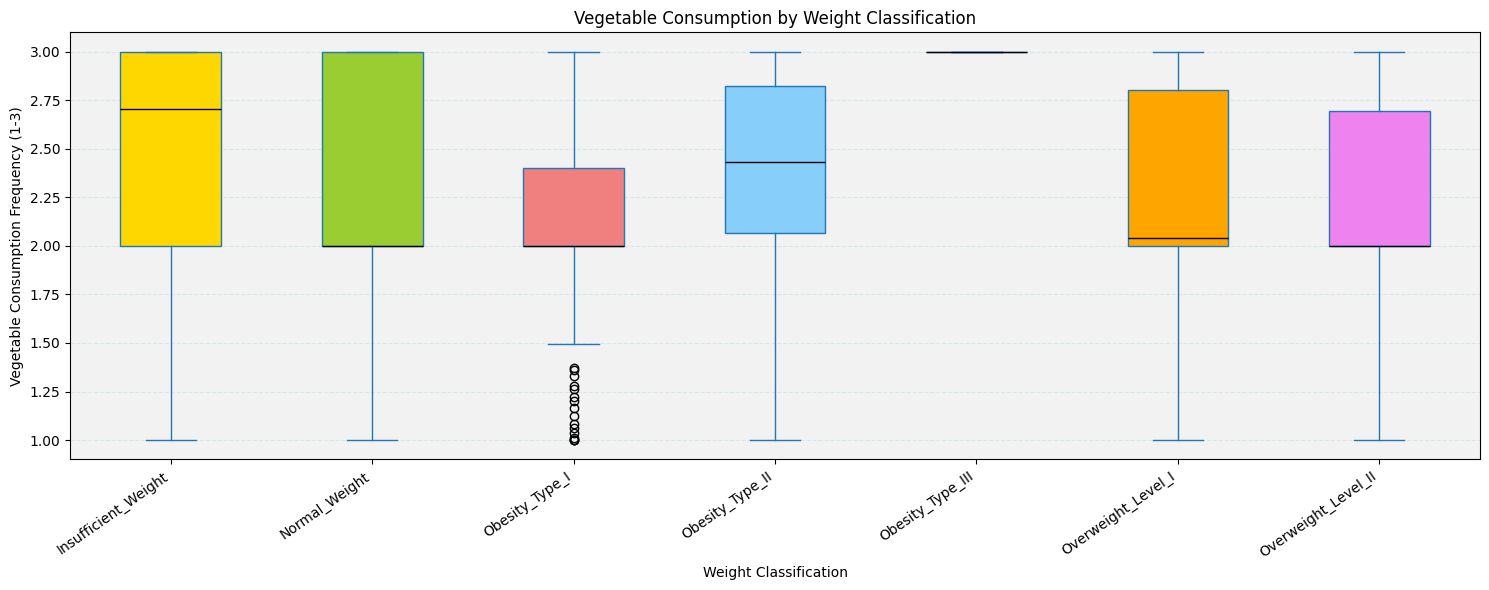

In [94]:
colors_list = [
    'gold', 'yellowgreen', 'lightcoral',
    'lightskyblue', 'lightgreen', 'orange', 'violet'
]

ax = vegetables.plot(
    kind='box',
    figsize=(15, 6),
    patch_artist=True,
    color={'medians': 'black'}
)

# Add colors
for box, color in zip(ax.patches, colors_list):
    box.set_facecolor(color)

# Background and grid
ax.set_facecolor('#F2F2F2')
ax.grid(axis='y', color='lightblue', linestyle='--', alpha=0.4)

plt.title('Vegetable Consumption by Weight Classification')
plt.xlabel('Weight Classification')
plt.ylabel('Vegetable Consumption Frequency (1-3)')
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()

## 8.3 Insights

1. Obesity Type III showed almost no variability in vegetable consumption, while the other classifications had a wider distribution, particularly Insufficient Weight and Normal Weight.
2. Obesity Type I was the only classification showing several lower outliers, with vegetable consumption values between approximately 1.0 and 1.4, which indicates observations that differ considerablywithin the weight group.

# [9. Q7:How does the distribution of weight classifications differ depending on frequent high-calorie food consumption?](#scrollTo=u9q-QGBEvqn_&line=14&uniqifier=1) **Lineplot**

## 9.1 Pivot table

In [95]:

calorie_pivot = pd.pivot_table(
    ndf,
    index='Weight_class',
    columns='High_calorie',
    aggfunc='size',
    fill_value=0
)

# Calculate percentages within each consumption group
calorie_pct = calorie_pivot.div(
    calorie_pivot.sum(axis=0),
    axis=1
) * 100

weight_order = [
    'Insufficient_Weight',
    'Normal_Weight',
    'Overweight_Level_I',
    'Overweight_Level_II',
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
]

calorie_pct = calorie_pct.loc[weight_order]

display(calorie_pct.round(1))

High_calorie,no,yes
Weight_class,,
Insufficient_Weight,20.6,11.8
Normal_Weight,32.1,11.1
Overweight_Level_I,9.1,13.8
Overweight_Level_II,30.5,11.7
Obesity_Type_I,4.5,18.4
Obesity_Type_II,2.9,15.7
Obesity_Type_III,0.4,17.5


## 9.2 Figure 7. Line Plot

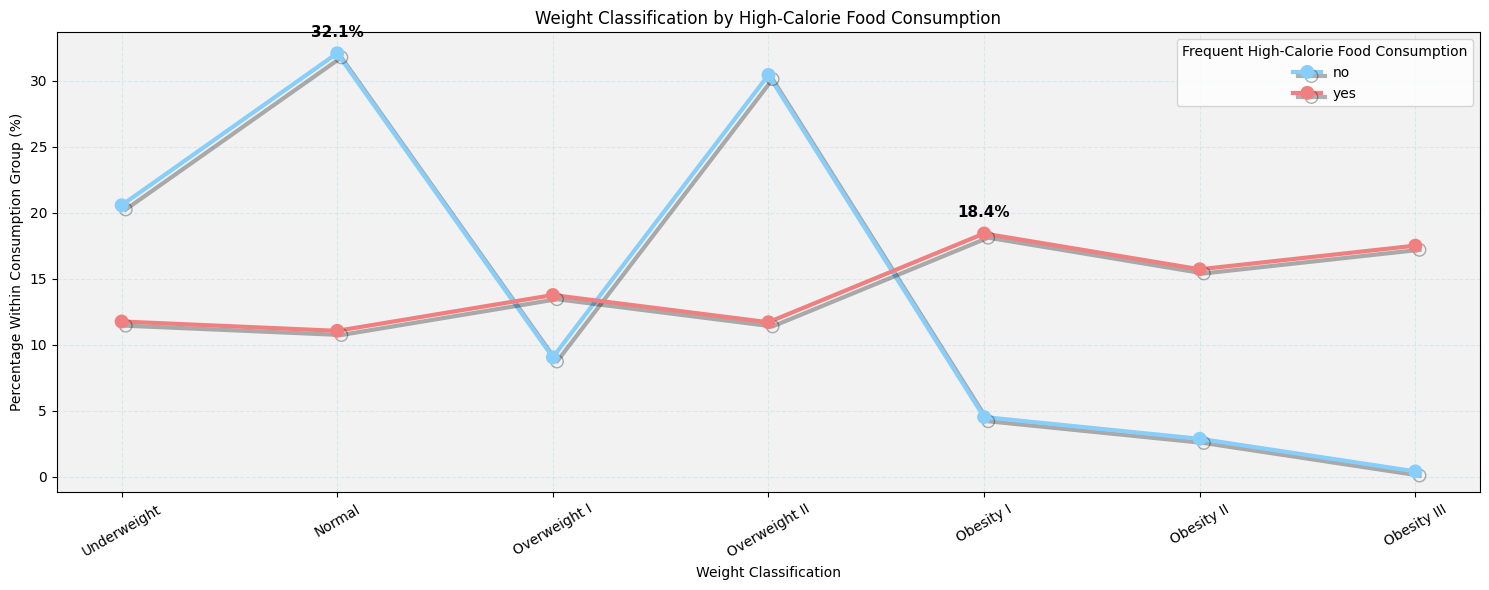

In [96]:
import matplotlib.patheffects as pe

ax = calorie_pct[['no', 'yes']].plot(
    kind='line',
    figsize=(15, 6),
    color=['lightskyblue', 'lightcoral'],
    marker='o',
    markersize=9,
    linewidth=3
)

for line in ax.lines:
    line.set_path_effects([
        pe.SimpleLineShadow(offset=(3, -3), alpha=0.3),
        pe.Normal()
    ])

ax.set_facecolor('#F2F2F2')
ax.grid(color='lightblue', linestyle='--', alpha=0.4)

plt.title('Weight Classification by High-Calorie Food Consumption')
plt.xlabel('Weight Classification')
plt.ylabel('Percentage Within Consumption Group (%)')

plt.xticks(
    range(7),
    ['Underweight', 'Normal', 'Overweight I', 'Overweight II',
     'Obesity I', 'Obesity II', 'Obesity III'],
    rotation=30
)

plt.legend(title='Frequent High-Calorie Food Consumption')
plt.tight_layout()

# Identify and label the highest point of each line

for col in calorie_pct.columns:

    peak = calorie_pct[col].max()
    peak_position = calorie_pct[col].argmax()

    ax.annotate(
        f'{peak:.1f}%',
        xy=(peak_position, peak),
        xytext=(0, 12),
        textcoords='offset points',
        ha='center',
        fontsize=11,
        fontweight='bold',
        color='black'
    )

plt.show()

## 9.3 Insights

1. Individuals who do not frequently consume high-calorie foods had their highest proportion in Normal Weight (32.1%), while those who frequently consume them peaked at Obesity Type I (18.4%).

2. Both groups show different distributions, when the high-colorie consumption is analyzed within the obesity weight classes.  Individuals who do not frequently consume high-calorie foods have considerably lower proportions in all three obesity types compared to those who frequently consume them.

# [10. Q8:To what extent does physical activity frequency explain variations in daily water intake](#scrollTo=u9q-QGBEvqn_&line=12&uniqifier=1)**Linear regression**

## 10.1 Pivot table

In [97]:


water_intake = pd.pivot_table(
    ndf,
    index=ndf.index,
    values=['Physical_Act', 'Water_intake']
)

display(water_intake.iloc[:5])

,Physical_Act,Water_intake
0,0.0,2.0
1,3.0,3.0
2,2.0,2.0
3,2.0,2.0
4,0.0,2.0


## 10.2 Figure 8. Linear regression model

In [98]:
import statsmodels.formula.api as smf

# Fit the OLS regression model
model_water = smf.ols(
    formula='Water_intake ~ Physical_Act',
    data=water_intake
).fit()

# Display the regression summary
model_water.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:           Water_intake   R-squared:                       0.027
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     58.58
Date:                Fri, 23 Oct 2026   Prob (F-statistic):           2.97e-14
Time:                        06:23:03   Log-Likelihood:                -1894.4
No. Observations:                2087   AIC:                             3793.
Df Residuals:                    2085   BIC:                             3804.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
================================================================================
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        1.8854      0.020     92.484      0.000       1.845       1.925
Physical_Act     0.1178      0.015      7.654      0.000       0.088       0.148
==============================================================================
Omnibus:                      205.200   Durbin-Watson:                   1.406
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               63.854
Skew:                          -0.103   Prob(JB):                     1.36e-14
Kurtosis:                       2.168   Cond. No.                         2.88
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [99]:
print('Intercept:', round(model_water.params['Intercept'], 3))
print('Physical activity coefficient:', round(model_water.params['Physical_Act'], 3))
print('R-squared:', round(model_water.rsquared, 3))
print('P-value:', round(model_water.pvalues['Physical_Act'], 4))

Intercept: 1.885
Physical activity coefficient: 0.118
R-squared: 0.027
P-value: 0.0


In [100]:
# Create results DataFrame
water_results = water_intake.copy()

# Add predicted values and residuals from OLS model
water_results['Predicted_Water'] = model_water.fittedvalues
water_results['Residual'] = model_water.resid

display(water_results.head(10))

,Physical_Act,Water_intake,Predicted_Water,Residual
0,0.0,2.0,1.885421,0.114579
1,3.0,3.0,2.238878,0.761122
2,2.0,2.0,2.121059,-0.121059
3,2.0,2.0,2.121059,-0.121059
4,0.0,2.0,1.885421,0.114579
5,0.0,2.0,1.885421,0.114579
6,1.0,2.0,2.003240,-0.003240
7,3.0,2.0,2.238878,-0.238878
8,1.0,2.0,2.003240,-0.003240
9,1.0,2.0,2.003240,-0.003240


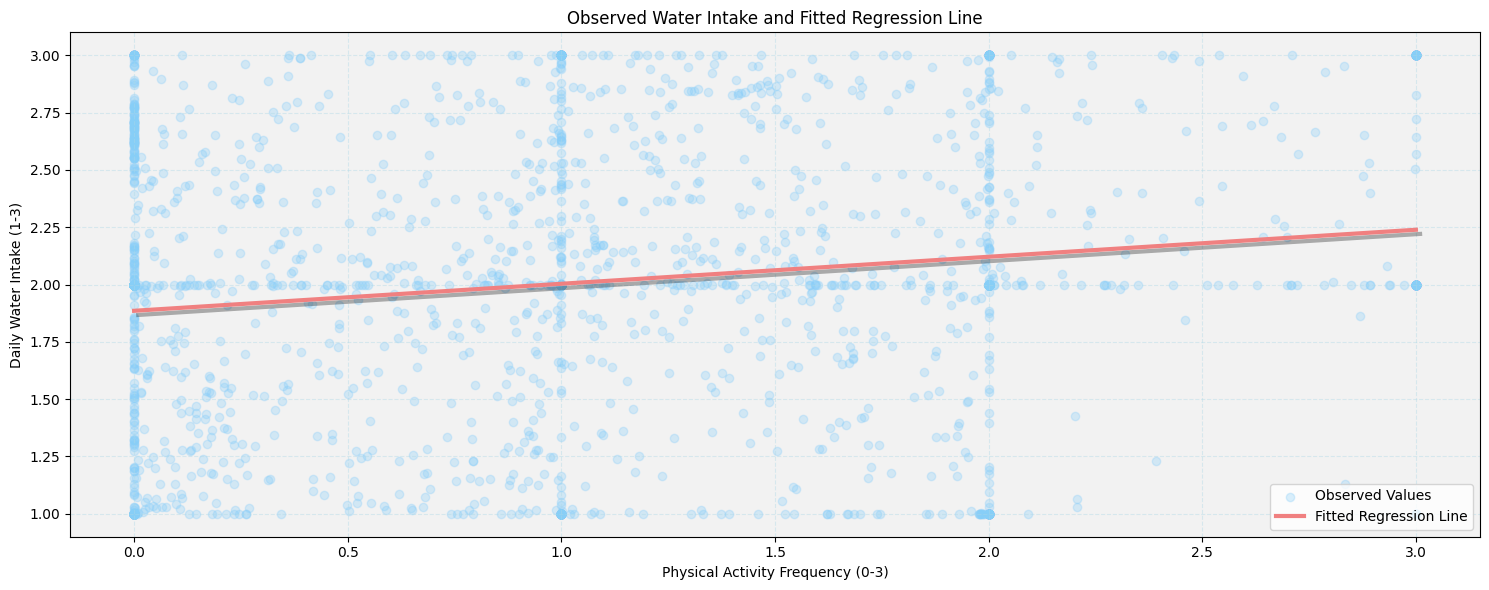

In [101]:
plt.figure(figsize=(15, 6))

# Plot observed values
plt.scatter(
    water_results['Physical_Act'],
    water_results['Water_intake'],
    color='lightskyblue',
    alpha=0.3,
    label='Observed Values'
)

# Sort values for the regression line
order = np.argsort(water_results['Physical_Act'].to_numpy())

# Plot fitted regression line
plt.plot(
    water_results['Physical_Act'].to_numpy()[order],
    water_results['Predicted_Water'].to_numpy()[order],
    color='lightcoral',
    linewidth=3,
    label='Fitted Regression Line'
)

# Background and grid
plt.gca().set_facecolor('#F2F2F2')
plt.grid(color='lightblue', linestyle='--', alpha=0.4)

plt.xlabel('Physical Activity Frequency (0-3)')
plt.ylabel('Daily Water Intake (1-3)')
plt.title('Observed Water Intake and Fitted Regression Line')
plt.legend()
plt.tight_layout()



plt.gca().lines[0].set_path_effects([
    pe.SimpleLineShadow(offset=(3, -3), alpha=0.3),
    pe.Normal()
])
plt.show()

## 10.3 Insights


1. The low R² (0.027) shows that the model explains only 2.7% of the variation in water intake, indicating that statistical significance does not necessarily imply strong predictive power.

##

# [Overall Conclusion](#scrollTo=u9q-QGBEvqn_&line=18&uniqifier=1)

Throughout the eight studies, I was able to identify different relationships between lifestyle habits, physical activity, and weight classification. One of the most important findings was the relationship between family history of overweight and obesity classification. Among individuals with a family history, 56.0% were classified with obesity, compared to only 2.2% of those without it. This shows a considerable difference between both groups.

Regarding eating habits, individuals who frequently consume high-calorie foods had higher proportions across the obesity classifications. However, vegetable consumption did not show a consistent pattern. For example, Obesity Type III showed almost no variability, while Obesity Type I presented several lower outliers. This suggests that not all eating habits follow the same patterns across weight classifications.

One result that I found interesting was the lack of a clear linear relationship between vegetable consumption and physical activity. Similarly, although the regression model showed a statistically significant relationship between physical activity and water intake, its R² of 0.027 indicates that only 2.7% of the variation was explained. Therefore, a statistically significant relationship does not necessarily mean that a variable has strong explanatory power.

